In [1]:
import sys
import pathlib
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt

# Add the parent directory to sys.path
sys.path.insert(0, str(pathlib.Path.cwd().parent))
#sys.path.append(str(pathlib.Path(__file__).resolve().parent.parent))
import velogp

L = 1e6
origins = torch.tensor([2e5, 6e5], dtype=torch.int32)
h_tgrid = velogp.dtensor([0, 800, 2000])
g_xranges_l = torch.tensor([4.99e5, 8.99e5], dtype=torch.int32)
g_xranges_u = torch.tensor([5.01e5, 9.01e5], dtype=torch.int32)

m = velogp.VelocityModel.single_chromosome(L, True, origins, ["C", "X"], h_tgrid, g_xranges_l, g_xranges_u,
                        ["site1", "site2"], torch.zeros(2, dtype=torch.int32),
                        velogp.dtensor(10), velogp.dtensor(1e4))
m.temporal.growthrate.copy_(velogp.dtensor(1.0/3600))
m.temporal.v0 = velogp.dtensor(50)
m.chromosomes[0].delay_scaled[:] = velogp.dtensor([0, 3.0])
m.temporal.h_log_raw[:] = torch.log(torch.tensor([1, 0.5, 2], dtype=torch.double))
m.chromosomes[0].g_delta = torch.tensor([100, 50], dtype=torch.double)

m0 = velogp.VelocityModel.single_chromosome(L, True, origins, ["C", "X"], h_tgrid, g_xranges_l, g_xranges_u,
                        ["site1", "site2"], torch.zeros(2, dtype=torch.int32),
                        velogp.dtensor(10), velogp.dtensor(1e4))
m0.temporal.growthrate.copy_(velogp.dtensor(1.0/3600))
m0.temporal.v0 = velogp.dtensor(50)

x = torch.linspace(0, L, steps=1001)
p = m.P(x).detach().numpy()
p0 = m0.P(x).detach().numpy()

In [2]:
pub_clean_style = {
    # Figure & Typography
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"],
    "font.size": 8,
    "figure.figsize": (7, 3),
    "figure.dpi": 600,
    
    # Axes Aesthetics
    "axes.linewidth": 0.8,
    "axes.edgecolor": "#111111",
    "axes.facecolor": "white",
    "axes.labelsize": 0.8*8,
    "axes.labelweight": "normal",
    "axes.titlesize": 8,
    "axes.titleweight": "normal",
    "axes.titlepad": 8,
    "axes.spines.top": False,     # Clean modern look by removing top spine
    "axes.spines.right": False,   # Clean modern look by removing right spine
    
    # Color Cycle (Professional, high-contrast publication palette)
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]),
    
    # Ticks Configurations
    "xtick.major.size": 5,
    "xtick.minor.size": 3,
    "xtick.major.width": 0.8,
    "xtick.labelsize": 0.8*8,
    "xtick.direction": "out",
    "ytick.major.size": 5,
    "ytick.minor.size": 3,
    "ytick.major.width": 0.8,
    "ytick.labelsize": 0.8*8,
    "ytick.direction": "out",

    # Lines
    "lines.linewidth": 0.8,
    
    # Grid (Light and non-obtrusive, if used)
    "axes.grid": False,           # Turn off default heavy grid
    "grid.color": "#EAEAEA",
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
    
    # Legend
    "legend.frameon": False,      # No background box for cleaner look
    "legend.fontsize": 0.8*8,
    "legend.loc": "best",
    
    # Saving figures
    "savefig.bbox": "tight",
    "savefig.dpi": 300            # Journal-quality resolution
}

plt.rcParams.update(pub_clean_style)

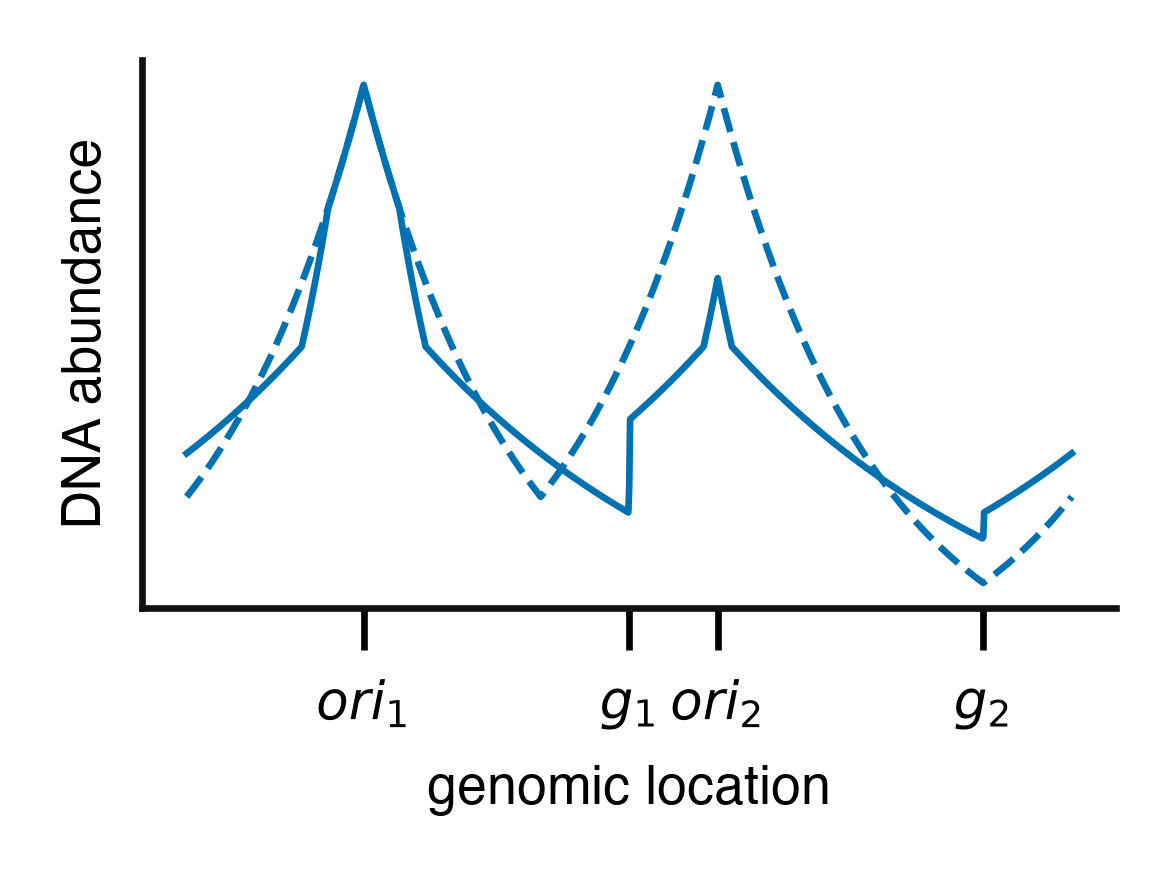

In [5]:
plt.figure(figsize=(2, 1.5))
line1, = plt.plot(x, p, label="v=v(t)")
plt.plot(x, p0, color=line1.get_color(), linestyle="dashed")
plt.xlabel("genomic location")
plt.ylabel("DNA abundance")
plt.xticks([2e5, 5e5, 6e5, 9e5], ["$ori_1$", "$g_1$", "$ori_2$", "$g_2$"])
plt.yticks([])
plt.tight_layout()
plt.savefig("../fig1-abd.pdf", format="pdf")

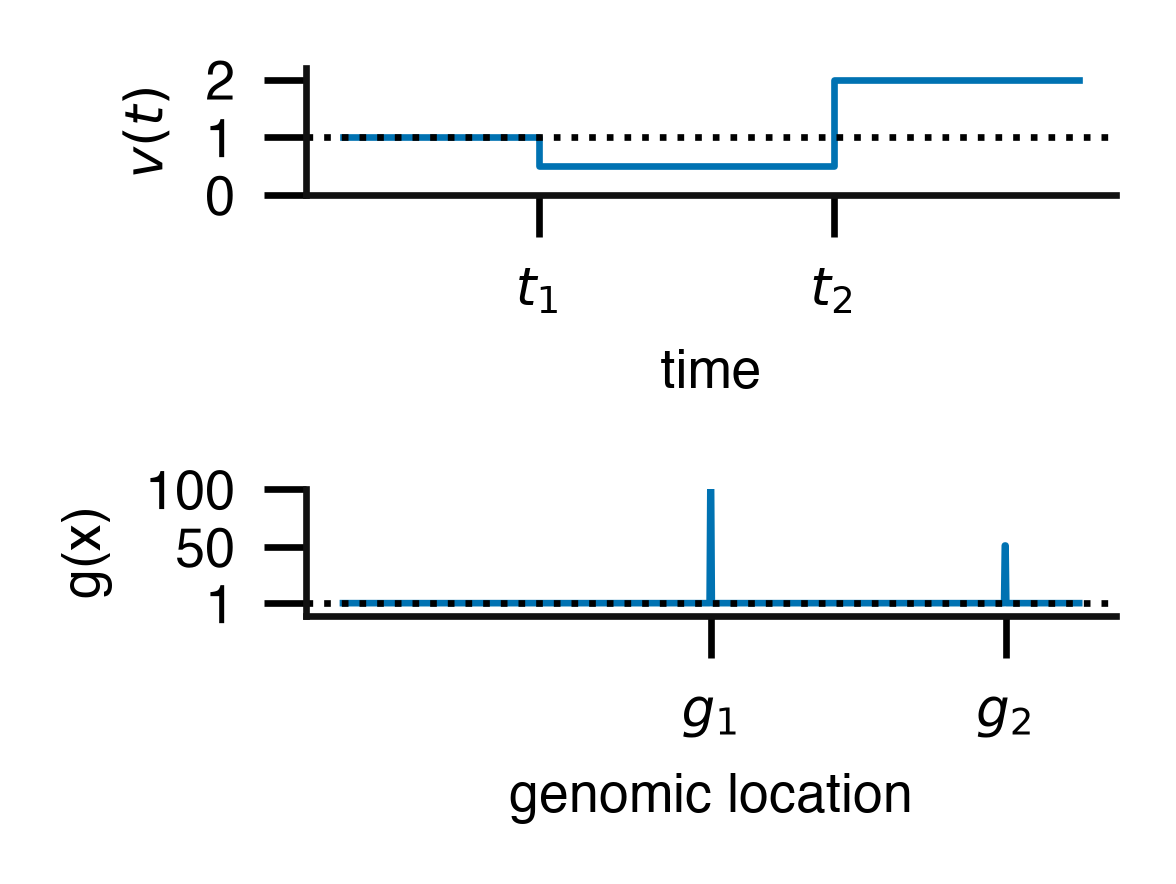

In [6]:
fig, axes = mpl.pyplot.subplots(nrows=2, ncols=1, figsize=(2, 1.5))
axes[0].step(torch.cat([h_tgrid, velogp.dtensor([3000])]),
             torch.cat([torch.exp(m.temporal.h_log_raw), velogp.dtensor([2.0])]), where='post', label="v(t)")
axes[0].axhline(1.0, color="black", linestyle="dotted")
axes[0].set_ylim(0, 2.2)
axes[0].set_yticks([0, 1, 2])
axes[0].set_xticks([800, 2000], ["$t_1$", "$t_2$"])
axes[0].set_xlabel("time")
axes[0].set_ylabel("$v(t)$")
axes[1].plot(x, m.chromosomes[0].g_fun(x).detach().numpy(), label="$g(x)$")
axes[1].axhline(1.0, color="black", linestyle="dotted")
axes[1].set_xlabel("genomic location")
axes[1].set_xticks([5e5, 9e5], ["$g_1$", "$g_2$"])
axes[1].set_ylim(-10, 100)
axes[1].set_yticks([1,50, 100], ["1", "50", "100"])
axes[1].set_ylabel("g(x)")
axes[1].minorticks_off()
plt.tight_layout()
plt.savefig("../fig1-vg.pdf", format="pdf")
plt.show()